# RFI: end-to-end example

Score the route freedom of real areas.

- **Sections 1-5** walk through the pipeline for **one** area, step by step
  (`parse_area` → `build_network` → `score_network`).
- **Section 6** is the one-line `rfi(area)` call that wraps all of it.
- **Section 7** compares **2 to 4 areas** side by side, with tables and plots.

Requires `pip install -e ".[notebook]"` and internet for the first download (cached afterwards).

In [1]:
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection
from matplotlib.patches import Ellipse
from scipy.sparse.csgraph import dijkstra

from rfi import constants as C
from rfi.metric import pair_score, score_network
from rfi.parser.area import parse_area
from rfi.parser.network import build_network

C.CACHE_DIR = str(Path.cwd().parent / "cache")  # share the repo-level cache when run from notebooks/
EPS, SEED = 0.1, 0

## 1. Area

Any of the four input forms works (see `rfi/parser/README.md`):

```python
parse_area("Le Marais, Paris")                                  # place name (needs internet)
parse_area((2.15, 41.38, 2.18, 41.40))                          # bbox (W, S, E, N)
parse_area({"point": (41.3910, 2.1650), "radius_m": 1500})      # point + radius
parse_area("area.geojson")                                      # polygon file
```

In [2]:
interior = parse_area("../polygons/valencia_central.geojson")  # default; swap in any line below
# interior = parse_area({"point": (41.3910, 2.1650), "radius_m": 1500})
# interior = parse_area("../polygons/valencia_central_big.geojson") # -- 0.329
# interior = parse_area("../polygons/moscow_central.geojson") -- 0.223
# interior = parse_area("../polygons/almaty_central.geojson") # -- 0.317
# interior = parse_area("../polygons/istanbul_beyoglu.geojson") -- 0.355
# interior = parse_area("../polygons/istanbul_central.geojson") -- 0.340
# interior = parse_area("../polygons/moscow_north.geojson") -- 0.253
# interior = parse_area("../polygons/spb_central.geojson") -- 0.240
# interior = parse_area("../polygons/valencia_central.geojson") -- 0.353
# interior = parse_area("../polygons/barcelona_central.geojson") -- 0.394
print(f"{interior.name}: {interior.area_km2:.2f} km², diameter {interior.diameter_m:.0f} m, {interior.utm_crs.name}")

valencia_central: 6.16 km², diameter 3625 m, WGS 84 / UTM zone 30N


## 2. Network

Downloads Overture segments and connectors for the interior plus a buffer, cleans them and builds the graph. The first run for a new area takes a minute or two; reruns read `cache/`.

In [3]:
built = build_network(interior, EPS)
print(built.meta)
pd.DataFrame(built.cleaning_stats).drop(columns="classes", errors="ignore").set_index("step")

16:19:26 INFO rfi.parser.network | download start cache=/Users/ivanesipov/Desktop/RFI/cache


16:19:26 INFO rfi.parser.network | cache hit folder=/Users/ivanesipov/Desktop/RFI/cache/2987a38f837a94a2f215bcc40153ddd1a1027b6b


16:19:26 INFO rfi.parser.network | download done elapsed_s=0.16 peak_rss_mb=339


16:19:26 INFO rfi.parser.network | filter start


16:19:26 INFO rfi.parser.network | walkable filter before=14576 after=11529 classes={'footway': 4033, 'residential': 2725, 'primary': 973, 'service': 827, 'pedestrian': 732, 'tertiary': 549, 'secondary': 541, 'cycleway': 475, 'steps': 193, 'unknown': 185, 'path': 177, 'living_street': 118, 'track': 1}


...

16:19:38 INFO rfi.parser.network | cleaning step=graph nodes=22148 edges=30578 length_km=903.27


16:19:38 INFO rfi.parser.network | cleaning step=isolated_removed nodes=20983 edges=29265 length_km=871.01


16:19:38 INFO rfi.parser.network | cleaning step=routing nodes=20983 edges=29256 length_km=871.01 interior_nodes=7148


{'overture_release': '2026-09-23.1', 'downloaded': '2026-10-18', 'n_nodes': 20983, 'n_edges': 29265}


,nodes,edges,length_km,connectors,interior_nodes
step,,,,,
download,NaN,14576,NaN,24676.0,NaN
walkable,NaN,11529,NaN,NaN,NaN
project,NaN,11529,903.26,NaN,NaN
split,NaN,30589,903.27,NaN,NaN
graph,22148.0,30578,903.27,NaN,NaN
isolated_removed,20983.0,29265,871.01,NaN,NaN
routing,20983.0,29256,871.01,NaN,7148.0


Text(0.5, 1.0, '20,983 nodes, 29,265 edges, 871 km')

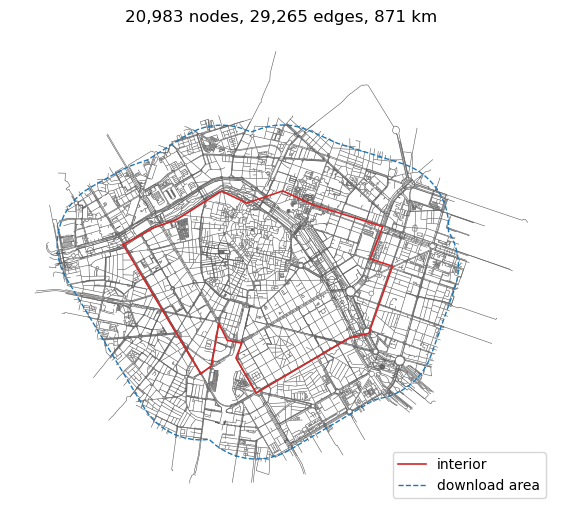

In [4]:
import pyproj
from shapely import ops

to_utm = pyproj.Transformer.from_crs(4326, interior.utm_crs, always_xy=True).transform
download_utm = ops.transform(to_utm, interior.download_geometry(EPS))

net, edges = built.net, built.edges
fig, ax = plt.subplots(figsize=(7, 7))
edges.plot(ax=ax, linewidth=0.4, color="0.35")
ax.plot(*interior.polygon_utm().exterior.xy, color="tab:red", lw=1.2, label="interior")
ax.plot(*download_utm.exterior.xy, color="tab:blue", ls="--", lw=1, label="download area")
ax.set_aspect("equal"); ax.set_axis_off(); ax.legend(loc="lower right")
ax.set_title(f"{len(net.xy):,} nodes, {len(net.u):,} edges, {net.length.sum() / 1000:.0f} km")

## 3. Score

`ellipse_ok` drops pairs whose reachable ellipse leaves the download area (the `boundary` exclusion).

Two numbers come out, both aggregated the same way (median per trip-length bin, then mean over the bins that are used):

- **RFI** = median of `r = U / A`, the share of the streets within reach that you can use.
- **U/d\*** (`redundancy`) = median of `U / d*`, metres of usable street per metre of shortest path. It grows with trip length (a longer trip has more room for detours), so read it per bin, not as one number across areas of different shape.

In [5]:
res = score_network(net, eps=EPS, seed=SEED, ellipse_ok=built.ellipse_ok)
print(f"RFI = {res['score']:.3f}   U/d* = {res['redundancy']:.2f}   (eps={EPS}, seed={SEED}, median circuity {res['circuity']:.2f})")
pd.DataFrame(res["bins"]).drop(columns="range_m").assign(
    bin_m=[f"{lo}-{hi}" for lo, hi in C.DIST_BINS]).set_index("bin_m").round(3)

16:19:40 INFO rfi.sampling | dijkstra start origins=150 nodes=20983


16:19:41 INFO rfi.sampling | dijkstra done elapsed_s=0.6 peak_rss_mb=512


16:19:41 INFO rfi.sampling | pairs kept=900 out_of_range=579 unreachable=0 too_circuitous=391 boundary=12


16:19:41 INFO rfi.metric | metric start pairs=900


16:19:43 INFO rfi.metric | metric done elapsed_s=1.96 peak_rss_mb=512


RFI = 0.308   U/d* = 13.59   (eps=0.1, seed=0, median circuity 1.21)


,bin,n_pairs,median_r,iqr_r,median_u_over_dstar,iqr_u_over_dstar,median_circuity,used
bin_m,,,,,,,,
300-750,0,300,0.271,0.132,5.164,3.255,1.267,True
750-1500,1,300,0.301,0.109,11.933,6.754,1.217,True
1500-3000,2,300,0.353,0.093,23.665,10.855,1.187,True


In [6]:
pd.DataFrame(res["diagnostics"]["bins"]).set_index("bin")  # exclusions per bin; column meanings: notebooks/METRICS.md

,candidates,unreachable,too_circuitous,boundary,kept
bin,,,,,
0,1972,0,207,0,300
1,4359,0,151,0,300
2,4265,0,33,12,300


## 4. Where is route freedom? (`edge_freedom`)

Share of in-ellipse trips for which each street is usable. Dark = streets that detours rarely use.

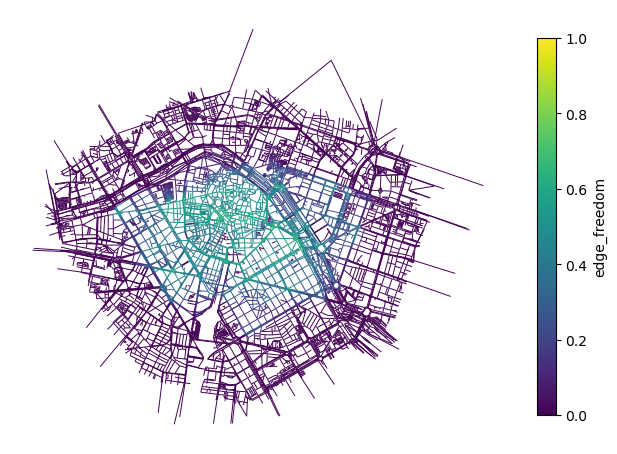

In [7]:
fig, ax = plt.subplots(figsize=(8, 7))
segs = np.stack([net.xy[net.u], net.xy[net.v]], axis=1)
lc = LineCollection(segs, linewidths=0.7, cmap="viridis")
lc.set_array(np.nan_to_num(res["edge_freedom"], nan=0.0)); lc.set_clim(0, 1)
ax.add_collection(lc); ax.autoscale(); ax.set_aspect("equal"); ax.set_axis_off()
fig.colorbar(lc, ax=ax, shrink=0.7, label="edge_freedom")

## 5. One trip in detail

Green = usable streets for this origin–destination pair within the budget, grey = inside the ellipse but not usable.

Text(0.5, 1.0, 'd*=2122 m   B=2334 m   U=41643   A=116480   r=0.358')

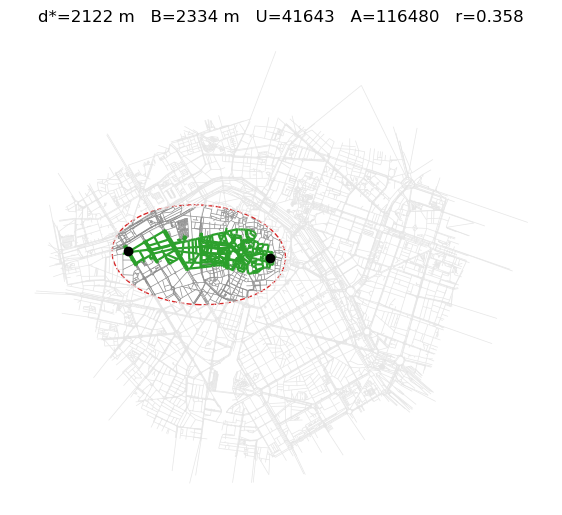

In [8]:
p = res["pairs"]
row = p[p["bin"] == 2].iloc[2]                      # first pair in the 750-1500 m bin
s, t = int(row["s"]), int(row["t"])
d = dijkstra(net.csr, directed=False, indices=[s, t])
U, A, usable, edge_in = pair_score(net, d[0], d[1], s, t, EPS)
B = (1 + EPS) * d[0][t]

fig, ax = plt.subplots(figsize=(7, 7))
col = np.where(usable, "tab:green", np.where(edge_in, "0.55", "0.9"))
ax.add_collection(LineCollection(segs, colors=col, linewidths=np.where(usable, 1.6, 0.5)))
(sx, sy), (tx, ty) = net.xy[s], net.xy[t]
c = np.hypot(tx - sx, ty - sy)
ax.add_patch(Ellipse(((sx + tx) / 2, (sy + ty) / 2), B, np.sqrt(B**2 - c**2),
                     angle=np.degrees(np.arctan2(ty - sy, tx - sx)), fill=False, ec="tab:red", ls="--"))
ax.plot([sx, tx], [sy, ty], "ko"); ax.autoscale(); ax.set_aspect("equal"); ax.set_axis_off()
ax.set_title(f"d*={d[0][t]:.0f} m   B={B:.0f} m   U={U:.0f}   A={A:.0f}   r={U / A:.3f}")

## 6. One call: `rfi()`

Everything above collapses to one call that returns a `Result` with the RFI, the redundancy `U/d*`,
the per-bin statistics, all scored pairs (`pairs`, with `U`, `A`, `r`, `u_over_dstar`) and the streets
with `edge_freedom`:

```python
from rfi import rfi

result = rfi({"point": (41.3910, 2.1650), "radius_m": 1500}, eps=0.1, seed=0)
result.score            # RFI
result.redundancy       # U/d*, saved next to it
result.save("results/eixample/")
```
or from the shell: `rfi score --point 41.3910,2.1650 --radius 1500 --out results/eixample/`.
Below, the same area as section 1, saved to `results/example/`.

In [9]:
from rfi import rfi

result = rfi(interior.polygon, eps=EPS, seed=SEED)
out_dir = Path.cwd().parent / "results" / "example"
result.save(out_dir)
print(f"RFI = {result.score:.3f}   U/d* = {result.redundancy:.2f}   saved to {out_dir}")
print(sorted(p.name for p in out_dir.iterdir()))
pd.DataFrame(result.bins).drop(columns="range_m").assign(
    bin_m=[f"{lo}-{hi}" for lo, hi in C.DIST_BINS]).set_index("bin_m").round(3)

16:19:45 INFO rfi | parse start eps=0.1 seed=0


16:19:45 INFO rfi | parse done elapsed_s=0.0 peak_rss_mb=512


16:19:45 INFO rfi.parser.network | download start cache=/Users/ivanesipov/Desktop/RFI/cache


16:19:45 INFO rfi.parser.network | cache hit folder=/Users/ivanesipov/Desktop/RFI/cache/2987a38f837a94a2f215bcc40153ddd1a1027b6b


16:19:45 INFO rfi.parser.network | download done elapsed_s=0.12 peak_rss_mb=512


...

16:20:01 INFO rfi | done score=0.3082633482559251 redundancy=13.587383196582039 runtime_s=15.56


16:20:01 INFO rfi.result | save start out=/Users/ivanesipov/Desktop/RFI/results/example


16:20:01 INFO rfi.result | save done elapsed_s=0.11 peak_rss_mb=525


RFI = 0.308   U/d* = 13.59   saved to /Users/ivanesipov/Desktop/RFI/results/example
['edges.parquet', 'pairs.parquet', 'result.json']


,bin,n_pairs,median_r,iqr_r,median_u_over_dstar,iqr_u_over_dstar,median_circuity,used
bin_m,,,,,,,,
300-750,0,300,0.271,0.132,5.164,3.255,1.267,True
750-1500,1,300,0.301,0.109,11.933,6.754,1.217,True
1500-3000,2,300,0.353,0.093,23.665,10.855,1.187,True


## 7. Compare areas

List **2 to 4** areas in `AREAS` below. Each value is anything `rfi()` accepts: a GeoJSON path,
a place name, a bbox `(W, S, E, N)` or `{"point": (lat, lon), "radius_m": m}`. All areas are scored
with the same `EPS` and `SEED`, so the numbers are comparable in that respect.

How to read the comparison:

- **Different sizes and shapes** of the areas affect RFI too. For a clean comparison of places use
  `point + radius` with the same radius (1.5 km recommended).
- RFI is only comparable at the **same eps**. Compare `RFI` and the per-bin medians first, the
  structural measures second.

In [10]:
import logging
from rfi import baselines as bl
from rfi import rfi

logging.getLogger().setLevel("WARNING")  # keep the notebook quiet; set to INFO to see the pipeline
POLY = Path.cwd().parent / "polygons"

AREAS = {  # label -> area (2 to 4 entries)
    "Barcelona": POLY / "barcelona_central.geojson",
    "Valencia": POLY / "valencia_central_big.geojson",
    "Paris": POLY / "paris_tourist.geojson",
    "London": POLY / "london_tourist.geojson",
    # "Berlin East": POLY / "berlin_east.geojson",
    # "Berlin West": POLY / "berlin_west.geojson"
    # "Almaty": POLY / "almaty_central.geojson",
    # "Moscow": POLY / "moscow_central.geojson",
    # "Saint Petersburg": POLY / "spb_central.geojson",
    # "Minsk": POLY / "minsk_central.geojson"
}
if not 2 <= len(AREAS) <= 4:
    raise ValueError(f"compare 2 to 4 areas, got {len(AREAS)}")

COLORS = dict(zip(AREAS, ["#0072B2", "#D55E00", "#009E73", "#CC79A7"]))  # colour-blind safe
cmp = {label: rfi(str(a) if isinstance(a, Path) else a, eps=EPS, seed=SEED) for label, a in AREAS.items()}
print({label: round(r.score, 3) for label, r in cmp.items()})

16:20:06 WARNING city2graph.base | Removed 12 invalid geometries


16:20:28 WARNING city2graph.base | Removed 19 invalid geometries


16:21:03 WARNING city2graph.base | Removed 124 invalid geometries


16:21:48 WARNING city2graph.base | Removed 104 invalid geometries


{'Barcelona': 0.385, 'Valencia': 0.292, 'Paris': 0.319, 'London': 0.265}


### 7.1 Summary table

`bins_used` below 3/3 means a trip-length bin had too few pairs and was dropped from the mean.
`boundary` counts pairs whose detour ellipse left the downloaded area; `too_circuitous` counts pairs
with d* above 1.5 times the straight-line distance. `r_gt_1` must be 0. `U/d*` is the redundancy (usable street metres per metre of shortest path); compare it per bin in 7.2.

In [11]:
def summary_row(res):
    d, used = res.diagnostics, [b for b in res.bins if b["used"]]
    return {"RFI": res.score, "U/d*": res.redundancy, "circuity": res.circuity, "bins_used": f"{len(used)}/{len(res.bins)}",
            "pairs": int(sum(b["n_pairs"] for b in res.bins)), "area_km2": res.meta["area_km2"],
            "nodes": res.meta["n_nodes"], "edges": res.meta["n_edges"],
            "street_km": res.edges["length_m"].sum() / 1000,
            "too_circuitous": d["too_circuitous"], "boundary": d["boundary"], "r_gt_1": d["r_gt_1"]}

summary = pd.DataFrame({label: summary_row(r) for label, r in cmp.items()}).T
display(summary.astype({"RFI": float, "U/d*": float, "circuity": float, "area_km2": float, "street_km": float}).round(3))

for label, r in cmp.items():  # flag what makes a score less comparable
    for b, row in zip(r.bins, r.diagnostics["bins"]):
        reached = row["candidates"] - row["unreachable"] - row["too_circuitous"]
        if not b["used"]:
            print(f"{label}: bin {b['range_m']} dropped ({b['n_pairs']} pairs)")
        if reached and row["boundary"] / reached > C.BOUNDARY_DROP_WARN:
            print(f"{label}: bin {b['range_m']} lost {row['boundary'] / reached:.0%} of pairs to the "
                  "boundary check; RFI is biased upward")

,RFI,U/d*,circuity,bins_used,pairs,area_km2,nodes,edges,street_km,too_circuitous,boundary,r_gt_1
Barcelona,0.385,12.705,1.208,3/3,900,10.138,24091,31266,895.913,249,138,0
Valencia,0.292,13.585,1.224,3/3,900,21.445,37028,51513,1628.771,343,17,0
Paris,0.319,13.817,1.201,3/3,900,24.999,66134,85124,2011.500,270,43,0
London,0.265,12.439,1.247,3/3,900,25.000,61261,76966,1919.628,258,43,0


### 7.2 RFI and U/d* by trip length

Boxes are the distribution over pairs in each trip-length bin (median, quartiles, 1.5 IQR whiskers).
**Left:** `r = U / A`, dashed lines are each area's RFI. **Right:** `U / d*`, dashed lines are each area's
redundancy. U/d* rises with trip length in every area, which is why the bin, not the area mean, is the
fair way to compare it.

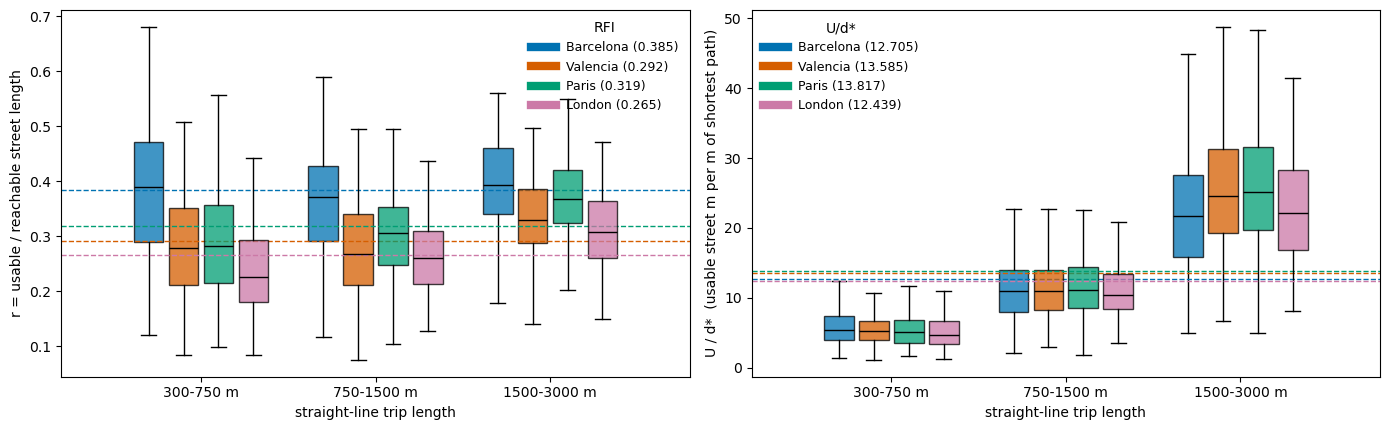

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
n, width = len(cmp), 0.8 / len(cmp)
panels = (("r", "score", "r = usable / reachable street length"),
          ("u_over_dstar", "redundancy", "U / d*  (usable street m per m of shortest path)"))
for ax, (col, agg, ylabel) in zip(axes, panels):
    for k, (label, r) in enumerate(cmp.items()):
        data = [r.pairs.loc[r.pairs["bin"] == b, col].to_numpy() for b in range(len(C.DIST_BINS))]
        pos = np.arange(len(data)) + (k - (n - 1) / 2) * width
        bp = ax.boxplot(data, positions=pos, widths=width * 0.85, patch_artist=True, showfliers=False,
                        medianprops={"color": "k"})
        for box in bp["boxes"]:
            box.set(facecolor=COLORS[label], alpha=0.75)
        ax.axhline(getattr(r, agg), color=COLORS[label], ls="--", lw=1)
        ax.plot([], [], color=COLORS[label], lw=6, label=f"{label} ({getattr(r, agg):.3f})")
    ax.set_xticks(range(len(C.DIST_BINS)), [f"{lo}-{hi} m" for lo, hi in C.DIST_BINS])
    ax.set_xlabel("straight-line trip length"); ax.set_ylabel(ylabel)
    ax.legend(frameon=False, fontsize=9, title="RFI" if col == "r" else "U/d*")
plt.tight_layout(); plt.show()

### 7.3 Where is route freedom? (`edge_freedom`, one picture per area, shared colour scale)

Each street is coloured by the share of in-ellipse trips that can use it. The colour scale is the same
in every picture, grey means the street was inside no trip ellipse. Black outline is the interior; the
bar is 1 km.

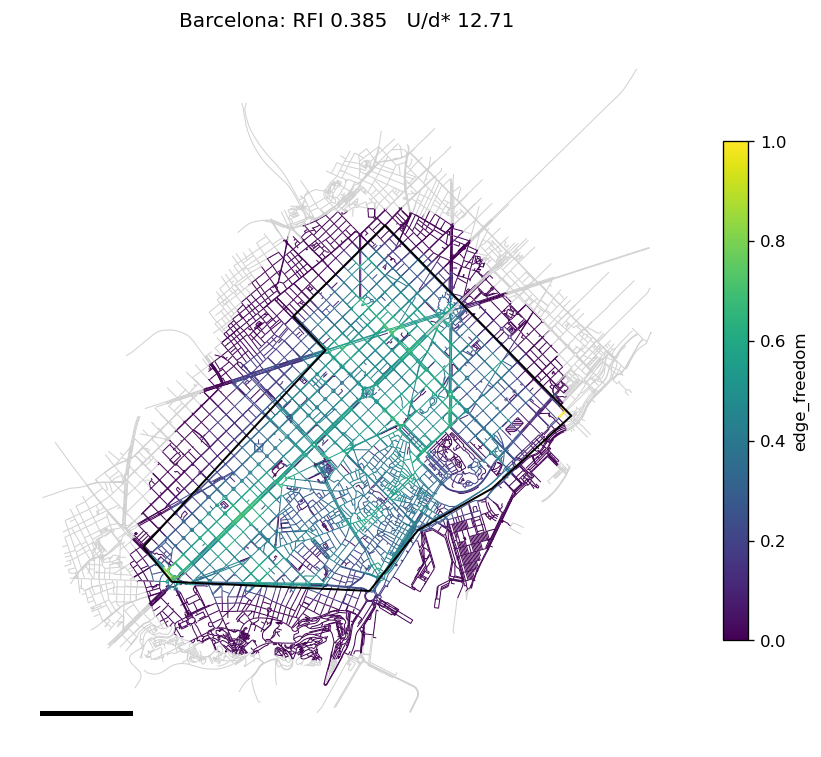

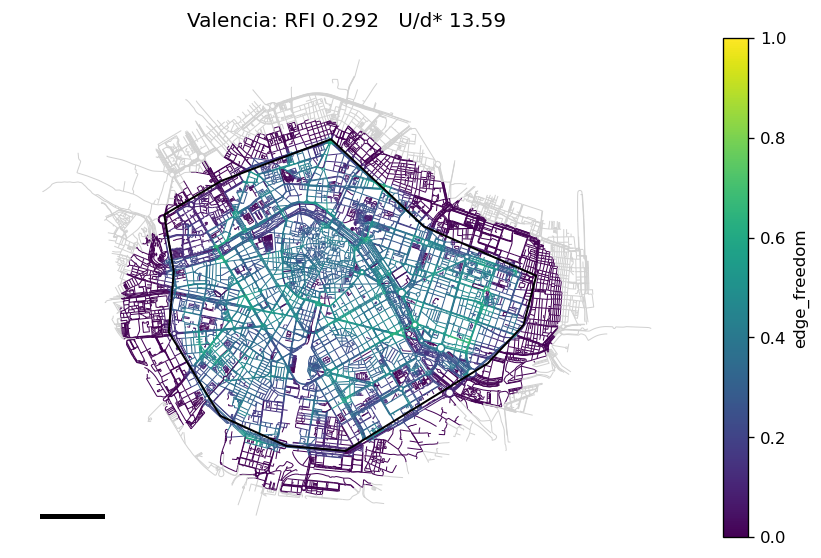

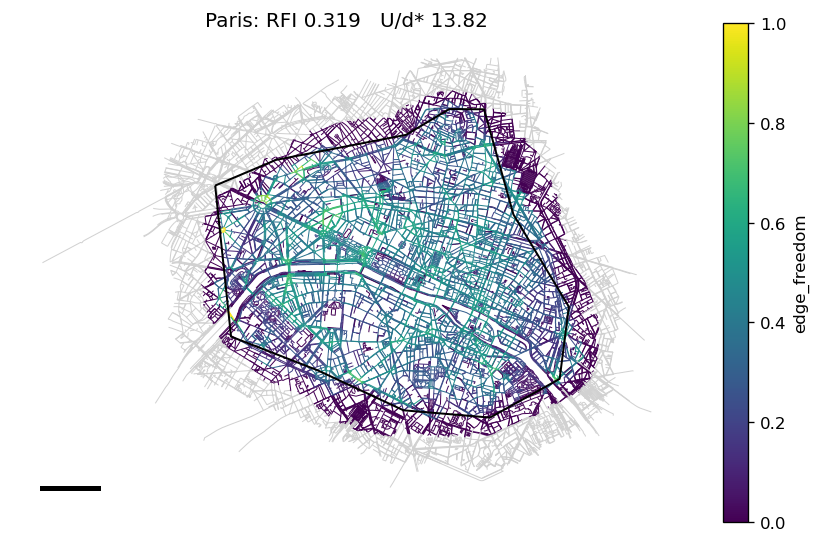

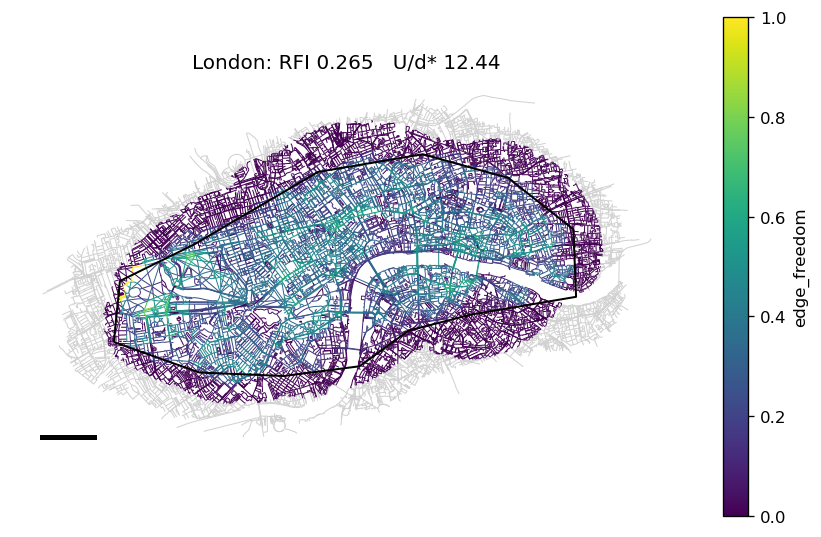

In [13]:
import geopandas as gpd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

for label, r in cmp.items():  # one figure per area
    fig, ax = plt.subplots(figsize=(9, 9), dpi=120)
    r.edges.plot(ax=ax, column="edge_freedom", cmap="viridis", vmin=0, vmax=1, linewidth=0.6,
                 missing_kwds={"color": "0.82"})
    gpd.GeoSeries.from_wkt([r.meta["interior_wkt"]], crs=4326).to_crs(r.edges.crs).boundary.plot(
        ax=ax, color="k", linewidth=1.2)
    x0, y0, x1, y1 = r.edges.total_bounds
    ax.plot([x0, x0 + 1000], [y0, y0], color="k", lw=3)
    ax.set_title(f"{label}: RFI {r.score:.3f}   U/d* {r.redundancy:.2f}"); ax.set_aspect("equal"); ax.set_axis_off()
    fig.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap="viridis"), ax=ax, shrink=0.6, label="edge_freedom")
    plt.show()

### 7.4 Street structure around the score

The structural measures from `rfi/baselines.py`, for context: intersection density (degree >= 3 nodes
per km2), mean circuity (edge length over straight length), orientation entropy (nats; max 3.58 =
all directions equally common, low = a dominant grid), link-node ratio, and route directness (median
d*/straight-line over the scored pairs). The rose shows the street bearings.

,intersections / km2,mean circuity,orientation entropy,link-node ratio,route directness,RFI
Barcelona,522.569000,1.013000,3.036000,1.317000,1.208000,0.385000
Valencia,722.932000,1.027000,3.454000,1.397000,1.224000,0.292000
Paris,777.558000,1.019000,3.538000,1.288000,1.201000,0.319000
London,782.815000,1.032000,3.552000,1.257000,1.247000,0.265000


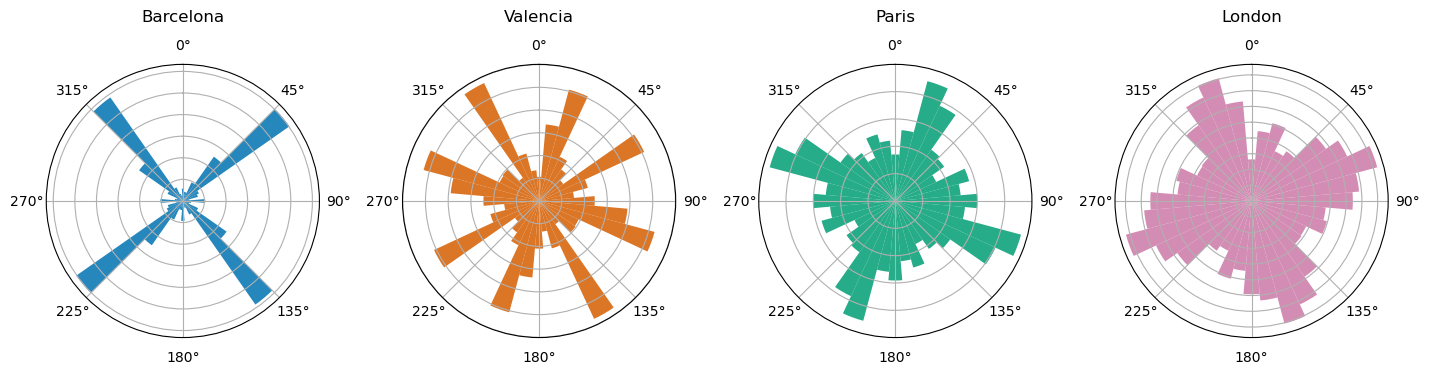

In [14]:
nets = {label: r.network() for label, r in cmp.items()}
ctx = pd.DataFrame({label: {
    "intersections / km2": bl.intersection_density(nets[label], r.meta["area_km2"]),
    "mean circuity": bl.mean_circuity(nets[label]),
    "orientation entropy": bl.orientation_entropy(nets[label]),
    "link-node ratio": bl.link_node_ratio(nets[label]),
    "route directness": bl.route_directness(r.pairs)} for label, r in cmp.items()}).T
display(ctx.assign(RFI=summary["RFI"].astype(float)).round(3)
        .style.background_gradient(cmap="Blues", axis=0))

fig, axes = plt.subplots(1, len(cmp), figsize=(3.6 * len(cmp), 3.6), subplot_kw={"projection": "polar"})
for ax, label in zip(np.atleast_1d(axes), cmp):
    counts, edges_ = np.histogram(bl.street_bearings(nets[label]), bins=36, range=(-5, 355))
    ax.bar(np.radians(edges_[:-1] + 5), counts / counts.sum(), width=np.radians(10), align="center",
           color=COLORS[label], alpha=0.85)
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1); ax.set_yticklabels([])
    ax.set_title(label, pad=12)
plt.tight_layout(); plt.show()

### 7.5 The same trip length, area by area

In each area the pair closest to 1000 m straight-line distance (from the 750-1500 m bin). Green is
usable for this trip, dark grey is inside the ellipse but unusable, dashed red is the ellipse
`euclid(s,x) + euclid(x,t) <= (1+eps)·d*`.

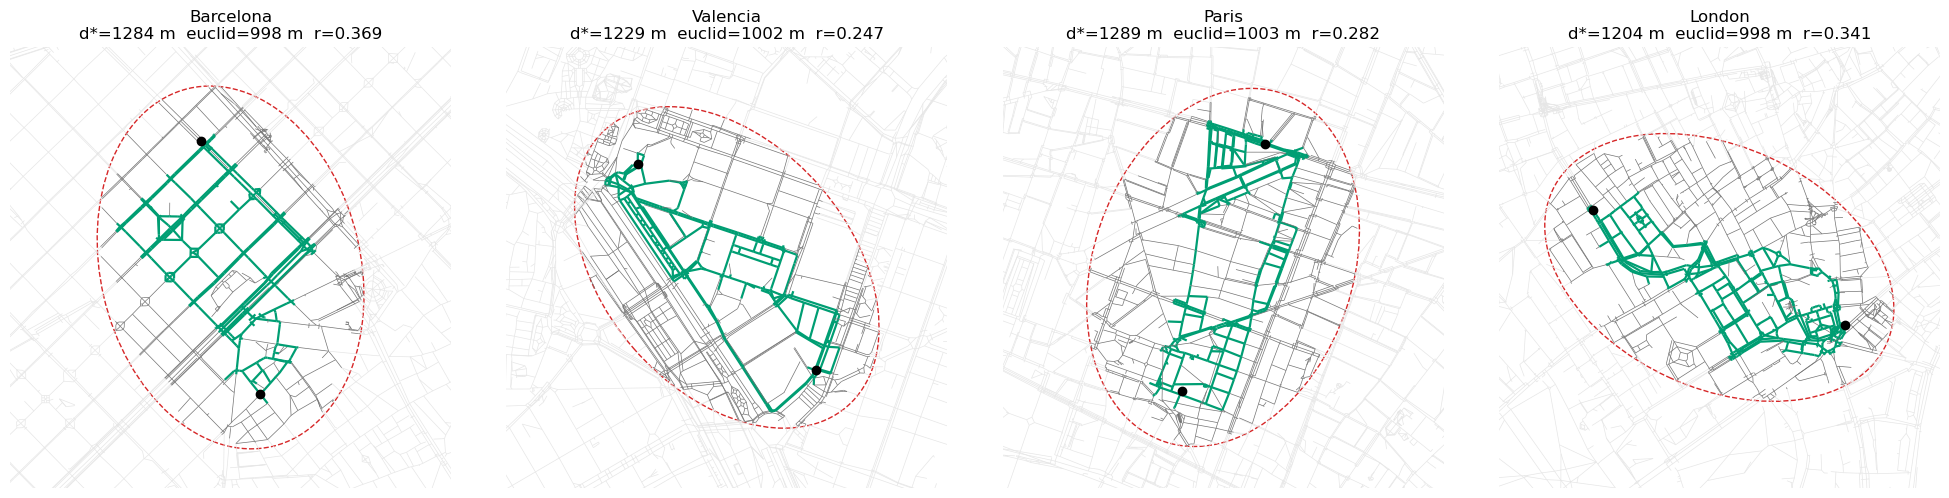

In [15]:
fig, axes = plt.subplots(1, len(cmp), figsize=(5 * len(cmp), 5), squeeze=False)
for ax, (label, r) in zip(axes[0], cmp.items()):
    net, p = nets[label], r.pairs[r.pairs["bin"] == 1]
    row = p.iloc[(p["euclid"] - 1000).abs().argmin()]
    s, t = int(row["s"]), int(row["t"])
    d = dijkstra(net.csr, directed=False, indices=[s, t], limit=C.dijkstra_cutoff_m(EPS))
    U, A, usable, edge_in = pair_score(net, d[0], d[1], s, t, EPS)
    budget = (1 + EPS) * d[0][t]
    segs_ = np.stack([net.xy[net.u], net.xy[net.v]], axis=1)
    col = np.where(usable, "#009E73", np.where(edge_in, "0.45", "0.9"))
    ax.add_collection(LineCollection(segs_, colors=col, linewidths=np.where(usable, 1.6, 0.5)))
    (sx, sy), (tx, ty) = net.xy[s], net.xy[t]
    c = np.hypot(tx - sx, ty - sy)
    ax.add_patch(Ellipse(((sx + tx) / 2, (sy + ty) / 2), budget, np.sqrt(budget**2 - c**2),
                         angle=np.degrees(np.arctan2(ty - sy, tx - sx)), fill=False, ec="tab:red", ls="--"))
    ax.plot([sx, tx], [sy, ty], "ko")
    pad = budget * 0.6
    ax.set_xlim((sx + tx) / 2 - pad, (sx + tx) / 2 + pad); ax.set_ylim((sy + ty) / 2 - pad, (sy + ty) / 2 + pad)
    ax.set_aspect("equal"); ax.set_axis_off()
    ax.set_title(f"{label}\nd*={d[0][t]:.0f} m  euclid={c:.0f} m  r={U / A:.3f}")
plt.tight_layout(); plt.show()